# Predição de evasão no ensino superior

**TCC — Sistemas de Informação · UEMG** · Guilherme Reis Pereira


Cada número abaixo é **recalculado a partir dos artefatos do pipeline** no momento em que o notebook
roda. Nada está digitado à mão, então a apresentação não pode divergir do que os notebooks produziram.

| | |
|---|---|
| Notebooks | 9 executados |
| Documentação | 14 documentos|

In [1]:
import json, os, warnings
import joblib, numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 150, "display.max_colwidth", 46)

D, F, M = "dados", "figuras", "modelos"
ler = lambda n, **k: pd.read_csv(os.path.join(D, n), **k)
fig = lambda n: display(Image(filename=os.path.join(F, n), width=980))

META      = json.loads(open(os.path.join(D, "metadados.json"), encoding="utf-8").read())
limpo     = ler("dataset_limpo.csv")
metricas  = ler("metricas_modelos.csv", index_col=0)
curva     = ler("curva_custo_exata.csv")
sementes  = ler("numeros_operacionais_semente.csv")
grupos    = ler("shap_grupos_conceituais.csv")
variaveis = ler("shap_variaveis_recompostas.csv")
condic    = ler("taxa_condicional_falsos_negativos.csv", index_col=0)
equidade  = ler("auditoria_equidade_resumo.csv")
ativos    = ler("alunos_ativos_priorizados.csv")

print(f"artefatos carregados · {len(limpo)} alunos · {META['n_features']} features")

artefatos carregados · 4424 alunos · 105 features


---
## Fase 1 · Entendimento dos dados

4.424 alunos, 36 variáveis, dados do Instituto Politécnico de Portalegre (2008–2019). Zero nulos,
zero duplicatas.

**O ponto desta fase não é a exploração — é uma falha de integridade que encontrei na origem.**

In [2]:
print("DISTRIBUIÇÃO DA VARIÁVEL-ALVO")
for k, v in limpo.target.value_counts().items():
    print(f"   {k:<10} {v:>5}  ({v/len(limpo):>5.1%})")

# A Fase 2 antecede a remoção de Enrolled (Fase 3): os descritivos usam os 4.424,
# que é a base sobre a qual o doc 01 foi escrito.
evadiu = (limpo.target == "Dropout").astype(int)
print()
print("TAXA DE EVASÃO POR FATOR — sobre os 4.424, como no doc 01")
for col, rot in [("tuition_fees_up_to_date", "Mensalidades em dia"),
                 ("scholarship_holder", "Bolsista"), ("debtor", "Inadimplente")]:
    g = evadiu.groupby(limpo[col]).mean()
    print(f"   {rot:<22} não: {g[0]:>6.1%}   sim: {g[1]:>6.1%}")

DISTRIBUIÇÃO DA VARIÁVEL-ALVO
   Graduate    2209  (49.9%)
   Dropout     1421  (32.1%)
   Enrolled     794  (17.9%)

TAXA DE EVASÃO POR FATOR — sobre os 4.424, como no doc 01
   Mensalidades em dia    não:  86.6%   sim:  24.7%
   Bolsista               não:  38.7%   sim:  12.2%
   Inadimplente           não:  28.3%   sim:  62.0%


### A falha de integridade

Ao carregar do MySQL, o ponto decimal havia sido lido como separador de milhar: `11.4375` virava
`114.375`, numa escala que vai de **0 a 20**.

| | |
|---|---|
| Notas corrompidas | **3.230** |
| Correção | Regra determinística — no máximo 2 dígitos inteiros, escala limitada a [0, 20] |
| Auditoria contra a fonte oficial (UCI) | **37 de 37 colunas idênticas, zero divergências** |

Uma guarda de faixa chegou a **abortar a primeira versão da regra**, que estava incompleta. O erro foi
pego pelo próprio código, não por inspeção.

In [3]:
# As notas corrompidas eram as SEMESTRAIS, cuja escala é [0, 20]. As notas de
# admissão e de formação anterior seguem outra escala (0-200) e não foram afetadas.
SEMESTRAIS = ["curricular_units_1st_sem_grade", "curricular_units_2nd_sem_grade"]
print("NOTAS SEMESTRAIS — escala [0, 20]. Foi esta verificação que abortou a regra incompleta.")
for c in SEMESTRAIS:
    v = limpo[c]
    print(f"   {c:<34} min {v.min():>6.2f}   max {v.max():>6.2f}   "
          f"fora da escala: {int(((v < 0) | (v > 20)).sum())}")
print("   (admission_grade e previous_qualification_grade seguem escala 0-200, não afetadas)")

print()
print("OUTLIERS PELO MÉTODO IQR, sobre as 19 contínuas — mantidos todos")
cont = META["cols_continuas"]
q1, q3 = limpo[cont].quantile(.25), limpo[cont].quantile(.75)
tem = ((limpo[cont] < q1 - 1.5*(q3-q1)) | (limpo[cont] > q3 + 1.5*(q3-q1))).any(axis=1)
print(f"   com ao menos um outlier : evasão {evadiu[tem].mean():>5.1%}  (n={int(tem.sum())})")
print(f"   sem nenhum outlier      : evasão {evadiu[~tem].mean():>5.1%}  (n={int((~tem).sum())})")
print()
print("   Se fossem ruído de medição as duas taxas seriam parecidas. São 3x diferentes:")
print("   removê-los descartaria preferencialmente a população-alvo do trabalho.")

NOTAS SEMESTRAIS — escala [0, 20]. Foi esta verificação que abortou a regra incompleta.
   curricular_units_1st_sem_grade     min   0.00   max  18.88   fora da escala: 0
   curricular_units_2nd_sem_grade     min   0.00   max  18.57   fora da escala: 0
   (admission_grade e previous_qualification_grade seguem escala 0-200, não afetadas)

OUTLIERS PELO MÉTODO IQR, sobre as 19 contínuas — mantidos todos
   com ao menos um outlier : evasão 45.7%  (n=2422)
   sem nenhum outlier      : evasão 15.6%  (n=2002)

   Se fossem ruído de medição as duas taxas seriam parecidas. São 3x diferentes:
   removê-los descartaria preferencialmente a população-alvo do trabalho.


---
## Fase 2 · Preparação dos dados

Três decisões sustentam a validade de tudo o que vem depois.

1. **Formulação binária** — `Enrolled` removida por ser *censura à direita*: não é desfecho, é ausência
   de desfecho.
2. **Split antes de qualquer transformação** — média, desvio e categorias são parâmetros estimados dos
   dados; aprendê-los antes do split contaminaria o teste.
3. **SMOTE só no treino**, dentro do `imblearn.Pipeline`, reaplicado por dobra na validação cruzada.

In [4]:
print("FORMULAÇÃO")
print(f"   classes            : {META['classes']}  ·  positiva: {META['classe_positiva']}")
print(f"   treino sem SMOTE   : {META['n_treino_antes_smote']}")
print(f"   treino com SMOTE   : {META['n_treino_apos_smote']}")
print(f"   teste (intocado)   : {META['n_teste']}  ·  evasão natural {META['prop_evasao_teste']:.1%}")
print()
print("CODIFICAÇÃO — 36 variáveis viram 105 features")
cont, binr = set(META["cols_continuas"]), set(META["cols_binarias"])
dummies = [f for f in META["features"] if f not in cont and f not in binr]
print(f"   {len(cont)} contínuas + {len(binr)} binárias + {len(dummies)} dummies = {META['n_features']}")
print()
print("A asserção que protege contra vazamento de SMOTE:")
y_te = ler("y_test.csv").iloc[:, 0]
print(f"   teste balanceado? {'SIM — FALHA' if abs(y_te.mean()-.5) < .02 else 'NÃO — ok'}"
      f"  (evasão {y_te.mean():.1%}, natural)")

FORMULAÇÃO
   classes            : {'0': 'Graduate', '1': 'Dropout'}  ·  positiva: Dropout
   treino sem SMOTE   : 2904
   treino com SMOTE   : 3534
   teste (intocado)   : 726  ·  evasão natural 39.1%

CODIFICAÇÃO — 36 variáveis viram 105 features
   19 contínuas + 8 binárias + 78 dummies = 105

A asserção que protege contra vazamento de SMOTE:
   teste balanceado? NÃO — ok  (evasão 39.1%, natural)


---
## Fase 3 · Modelagem

Três modelos, 1.755 ajustes de hiperparâmetros em busca exaustiva.

In [5]:
cols = ["F1", "recall", "precisão", "ROC-AUC", "PR-AUC"]
print("DESEMPENHO NO TESTE — 726 alunos nunca vistos, partição da semente 42")
print(metricas[cols].to_string(float_format=lambda v: f"{v:.4f}"))

lr, xgb = metricas.loc["Regressão Logística", "F1"], metricas.loc["XGBoost", "F1"]
print()
print(f"   ganho do XGBoost sobre a linha de base: {(xgb-lr)/lr:+.1%}")

DESEMPENHO NO TESTE — 726 alunos nunca vistos, partição da semente 42
                        F1  recall  precisão  ROC-AUC  PR-AUC
Regressão Logística 0.8938  0.9331    0.8576   0.9739  0.9710
Random Forest       0.9059  0.8979    0.9140   0.9726  0.9697
XGBoost             0.9059  0.8979    0.9140   0.9747  0.9741

   ganho do XGBoost sobre a linha de base: +1.4%


### O achado central

Os três modelos convergem para o mesmo patamar porque **o sinal está nos dados, não no algoritmo**. Não
havendo custo relevante de desempenho em escolher um modelo mais explicável, a **interpretabilidade
vira critério legítimo de decisão, não concessão** — é o argumento que sustenta o objetivo do TCC.

### E fica uma tensão em aberto

O critério de seleção é o **F1**, que trata falso negativo e falso positivo como se custassem igual. A
premissa declarada do trabalho é que **não custam**.

Repare na tabela acima: a **Regressão Logística tem o maior recall**. Se perder um evadido custa mais
que convocar alguém à toa, por que não escolher ela?

*A resposta depende de uma ferramenta que só aparece na próxima fase.*

---
## Fase 4 · Significância estatística

Antes de resolver a tensão, um resultado que mudou o trabalho inteiro: repeti o pipeline com
**10 sementes de partição diferentes**.

In [6]:
print("SEMENTE 42 CONTRA A PARTIÇÃO TÍPICA")
print(sementes.to_string(index=False))

SEMENTE 42 CONTRA A PARTIÇÃO TÍPICA
                        métrica  semente 42  média das 10   mínimo   máximo
                             F1      0.9059        0.8796   0.8656   0.8909
                         Recall      0.8979        0.8437   0.8239   0.8592
                       Precisão      0.9140        0.9191   0.8873   0.9412
Detectados de cada 100 evadidos     90.0000       84.0000  82.0000  86.0000
 Acerto de cada 100 sinalizados     91.0000       92.0000  89.0000  94.0000
          Verdadeiros positivos    255.0000      240.0000 234.0000 244.0000
               Falsos negativos     29.0000       44.0000  40.0000  50.0000
               Falsos positivos     24.0000       21.0000  15.0000  31.0000
             Alunos sinalizados    279.0000      261.0000 253.0000 275.0000


### Precisão na hora de falar isso

O viés está na **detecção** — recall e F1. A **precisão não teve o mesmo viés**: ficou levemente melhor
no típico, 92 contra 91.

A frase correta é *"a semente 42 foi otimista na detecção: 90 de cada 100 evadidos contra 84 típicos"*
— e não "o modelo é pior do que eu achava", que generalizaria indevidamente.

Nenhum modelo lidera de forma estável: em F1 o XGBoost vence em 6 das 10 sementes, a Regressão
Logística em 3 e a Random Forest em 1. Em **recall**, a Regressão Logística vence em **10 de 10**.

### Agora a tensão da Fase 3

O teste de **McNemar** confirma que ela é real: a Regressão Logística detecta significativamente mais
evadidos no limiar 0,50 (**p = 0,034**). Não é impressão.

Mas 0,50 é convenção de biblioteca. A **curva de custo exata** iguala os pontos de operação — para cada
número de evadidos detectados, o mínimo de falsos alarmes que cada modelo precisa. Sem interpolação:
resolução de um aluno.

In [7]:
N_TURMA, TETO = 726, 363          # teto prático: 50% da turma
sob = curva[curva.conv_xgboost <= TETO]
banda = curva[(curva.detectados >= 242) & (curva.detectados <= 272)]

print("ABAIXO DO TETO PRÁTICO DE 50% DA TURMA")
print(f"   pontos decididos              : {int((sob.dif != 0).sum())}")
print(f"   XGBoost detecta mais          : {int((sob.dif > 0).sum())}")
print(f"   Reg. Logística detecta mais   : {int((sob.dif < 0).sum())}")
print(f"   empatados                     : {int((sob.dif == 0).sum())}")
print()
print("NA FAIXA ONDE A DECISÃO SE DÁ — recall "
      f"{banda.recall.min():.4f} a {banda.recall.max():.4f}")
print(f"   XGBoost vence em {int((banda.dif > 0).sum())} de {len(banda)} pontos")
print()
inv = curva[curva.dif < 0]
bloco = inv[inv.detectados <= 276]
print("A EXCEÇÃO QUE NÃO ESCONDO")
print(f"   {len(bloco)} pontos da Reg. Logística convocam "
      f"{bloco.conv_xgboost.min()/N_TURMA:.0%} a {bloco.conv_xgboost.max()/N_TURMA:.0%} da turma "
      f"— DENTRO do teto de 50%")

ABAIXO DO TETO PRÁTICO DE 50% DA TURMA
   pontos decididos              : 76
   XGBoost detecta mais          : 72
   Reg. Logística detecta mais   : 4
   empatados                     : 200

NA FAIXA ONDE A DECISÃO SE DÁ — recall 0.8521 a 0.9577
   XGBoost vence em 31 de 31 pontos

A EXCEÇÃO QUE NÃO ESCONDO
   4 pontos da Reg. Logística convocam 47% a 49% da turma — DENTRO do teto de 50%


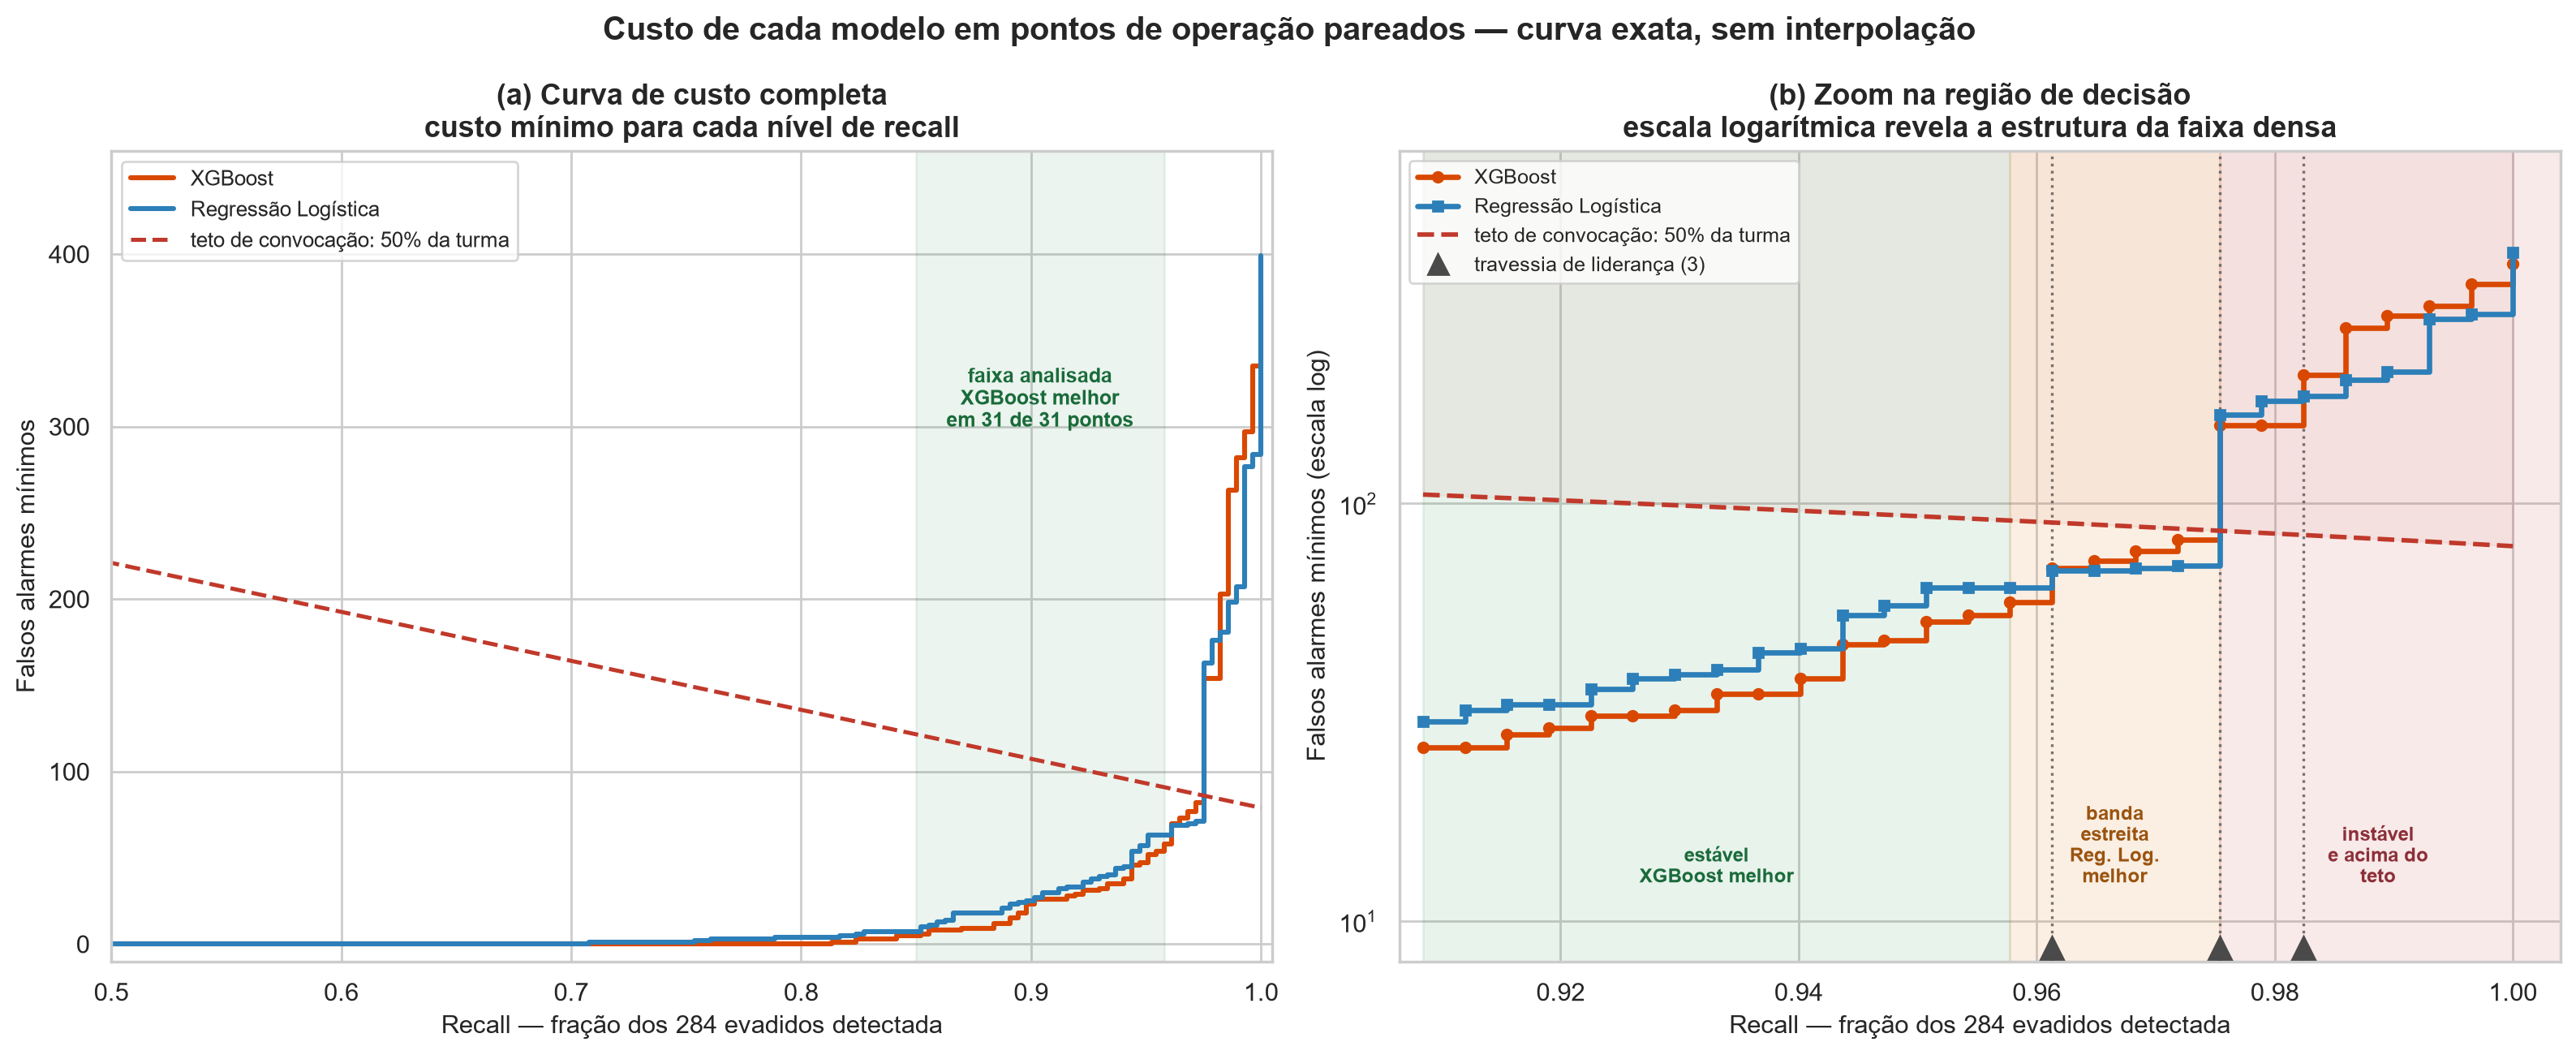

In [8]:
fig("25_curvas_custo_pareadas.png")

**Achado com destaque próprio:** o limiar 0,50 não é ótimo nem para a própria Regressão Logística. Isso
é evidência independente de que **o limiar é decisão institucional, não propriedade do modelo** — e
leva à hierarquia que proponho na monografia:

| Ordem | Decisão | Quem decide |
|---:|---|---|
| 1º | Política de custo | A instituição |
| 2º | Limiar que implementa a política | Derivado de 1 |
| 3º | Algoritmo | Técnico — a menos importante das três |

---
## Fase 5 · Interpretabilidade com SHAP

TreeSHAP: valores de Shapley **exatos**, não aproximados. Aditividade conferida.

In [9]:
print("IMPACTO POR GRUPO CONCEITUAL")
for _, r in grupos.iterrows():
    barra = "█" * int(round(r["% do total"] / 2))
    print(f"   {r.grupo:<26} {r['% do total']:>5.1f}%  {barra}")

print()
print("AS 5 VARIÁVEIS MAIS RELEVANTES (dummies recompostas)")
for _, r in variaveis.head(5).iterrows():
    print(f"   {int(r.posicao)}. {r.variavel:<38} {r['% do total']:>5.2f}%")
print()
print(f"   as duas primeiras somam {variaveis.head(2)['% do total'].sum():.1f}% de todo o impacto")

IMPACTO POR GRUPO CONCEITUAL
   Desempenho acadêmico        59.9%  ██████████████████████████████
   Situação financeira         14.9%  ███████
   Trajetória de ingresso       9.5%  █████
   Perfil demográfico           5.7%  ███
   Contexto macroeconômico      5.1%  ███
   Origem familiar              4.9%  ██

AS 5 VARIÁVEIS MAIS RELEVANTES (dummies recompostas)
   1. Disciplinas aprovadas (2º sem.)        24.93%
   2. Disciplinas aprovadas (1º sem.)        13.35%
   3. Mensalidades em dia                     6.84%
   4. Disciplinas matriculadas (1º sem.)      6.33%
   5. Média das notas (2º sem.)               4.05%

   as duas primeiras somam 38.3% de todo o impacto


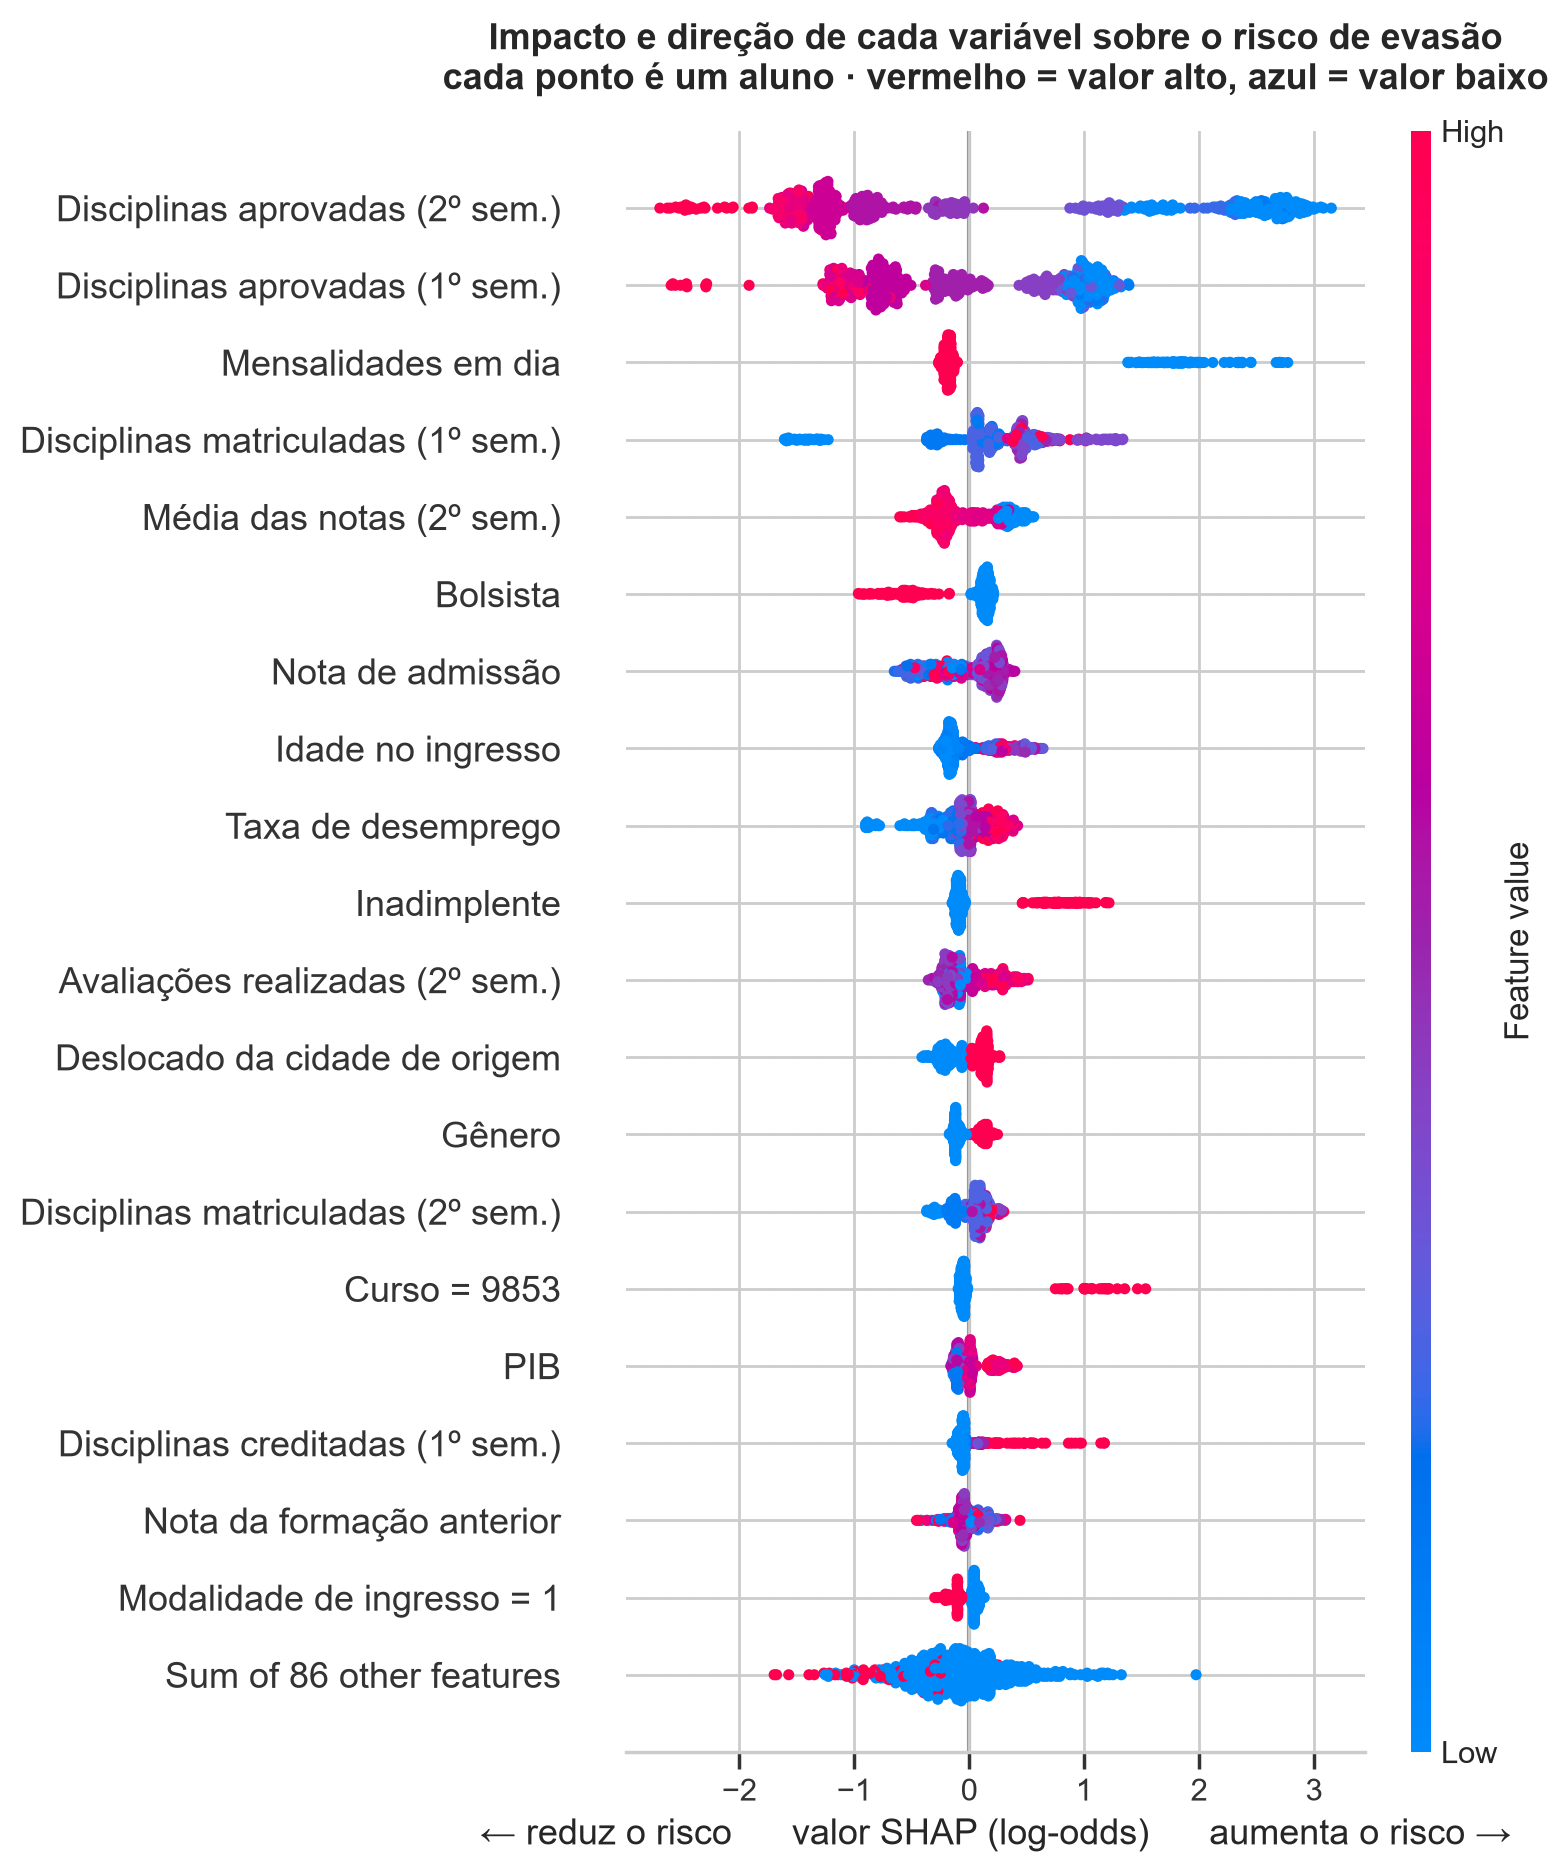

In [10]:
fig("13_shap_beeswarm.png")

---
## Fase 6 · Calibração de probabilidade

O escore do modelo é probabilidade real, ou apenas ordenação? Importa porque a análise de limiar o trata
como probabilidade.

In [12]:
from sklearn.metrics import brier_score_loss, roc_auc_score
X_te = ler("X_test.csv"); y_te = ler("y_test.csv").iloc[:, 0]
prob = joblib.load(os.path.join(M, "melhor_modelo.joblib")).predict_proba(X_te)[:, 1]

print(f"   Brier score : {brier_score_loss(y_te, prob):.4f}   (boa qualidade agregada)")
print(f"   ROC-AUC     : {roc_auc_score(y_te, prob):.4f}")
print()
print("CALIBRAÇÃO POR FAIXA — onde o erro está, e quantos alunos há nele")
print(f"   {'faixa':<12}{'n':>5}{'predito':>10}{'observado':>11}{'erro':>9}")
for lo, hi in [(0, .1), (.1, .2), (.2, .3), (.3, .5), (.5, .7), (.7, .9), (.9, 1.01)]:
    m = (prob >= lo) & (prob < hi)
    if not m.sum():
        continue
    marca = "  <-- a faixa crítica" if lo == .1 else ""
    print(f"   [{lo:.1f}-{hi:.1f}){int(m.sum()):>5}{prob[m].mean():>10.1%}"
          f"{y_te[m].mean():>11.1%}{prob[m].mean()-y_te[m].mean():>+9.1%}{marca}")

   Brier score : 0.0520   (boa qualidade agregada)
   ROC-AUC     : 0.9747

CALIBRAÇÃO POR FAIXA — onde o erro está, e quantos alunos há nele
   faixa           n   predito  observado     erro
   [0.0-0.1)  279      4.3%       2.2%    +2.1%
   [0.1-0.2)   81     14.2%       2.5%   +11.8%  <-- a faixa crítica
   [0.2-0.3)   36     24.4%      11.1%   +13.3%
   [0.3-0.5)   51     40.7%      33.3%    +7.4%
   [0.5-0.7)   29     60.6%      44.8%   +15.8%
   [0.7-0.9)   31     82.3%      74.2%    +8.1%
   [0.9-1.0)  219     98.1%     100.0%    -1.9%


### Testei recalibrar, e não adotei

| Método | Brier | ECE | Erro na faixa crítica |
|---|---:|---:|---:|
| **sem calibração** — adotado | 0,0520 | 0,1052 | +11,8 pp |
| sigmoid (Platt) | 0,0523 | 0,1189 | +8,4 pp |
| isotonic | 0,0516 | **0,0880** | +10,7 pp |

A isotônica melhora o ECE em **16%**, mas **nenhum método corrige a faixa que motivou a análise**.

E o argumento decisivo é outro: a calibração é **monotônica** — o ROC-AUC é idêntico nos três casos,
logo ela não altera a ordenação e **exatamente os mesmos alunos seriam convocados**. Muda o número
colado no aluno, não a decisão.

---
## Fase 7 · Equidade algorítmica

Um modelo que aciona intervenção precisa errar de forma parecida entre subgrupos. Errar mais em um grupo
significa deixar de socorrer justamente quem o sistema já atende pior.

In [13]:
e = equidade.copy()
e.columns = ["variável", "disp. recall (pp)", "disp. FPR (pp)", "menor recall",
             "maior recall", "p-valor", "significativo", "ICs disjuntos"]
print(e[["variável", "disp. recall (pp)", "p-valor", "significativo"]]
      .sort_values("disp. recall (pp)", ascending=False)
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

           variável  disp. recall (pp)  p-valor significativo
       Faixa etária              7.263    0.072           não
Deslocado da cidade              3.499    0.343           não
              Turno              2.920    0.534           não
           Bolsista              2.773    0.618           não
             Gênero              2.448    0.501           não


Com 726 alunos o teste **não tem poder** para separar diferenças pequenas. A conclusão honesta é **"não detectamos disparidade"** — que não é o mesmo
que "não existe disparidade". Ausência de evidência não é evidência de ausência.

---
## Fase 8 · Aplicação aos alunos ativos

Apliquei o modelo à classe `Enrolled`, removida do treino. É o uso pretendido do trabalho — e o teste
mais duro da limitação principal (**L-01**: treinei em trajetórias concluídas, mas o uso é sobre alunos
que ainda cursam).

In [14]:
pre = joblib.load(os.path.join(M, "preprocessador.joblib"))
mod = joblib.load(os.path.join(M, "melhor_modelo.joblib"))

def escores(sub):
    X = pd.DataFrame(pre.transform(sub.drop(columns=["target"])),
                     columns=pre.get_feature_names_out())
    return mod.predict_proba(X)[:, 1]

print("ONDE CADA GRUPO CAI NA ESCALA DO MODELO")
print(f"   {'grupo':<26}{'n':>6}{'mediana':>10}{'% na zona 0,2–0,8':>20}")
for alvo, rot in [("Dropout", "Dropout — evadiram"), ("Enrolled", "Enrolled — cursando"),
                  ("Graduate", "Graduate — formaram")]:
    s = escores(limpo[limpo.target == alvo])
    print(f"   {rot:<26}{len(s):>6}{np.median(s):>10.3f}{((s>=.2)&(s<=.8)).mean():>19.1%}")

s_at = escores(limpo[limpo.target == "Enrolled"])
print()
print(f"   limiar 0,50 sinalizaria {int((s_at>=.5).sum())} alunos "
      f"({(s_at>=.5).mean():.1%} dos ativos)")

ONDE CADA GRUPO CAI NA ESCALA DO MODELO
   grupo                          n   mediana   % na zona 0,2–0,8
   Dropout — evadiram          1421     0.984              17.5%
   Enrolled — cursando          794     0.480              42.4%
   Graduate — formaram         2209     0.058              13.1%

   limiar 0,50 sinalizaria 386 alunos (48.6% dos ativos)


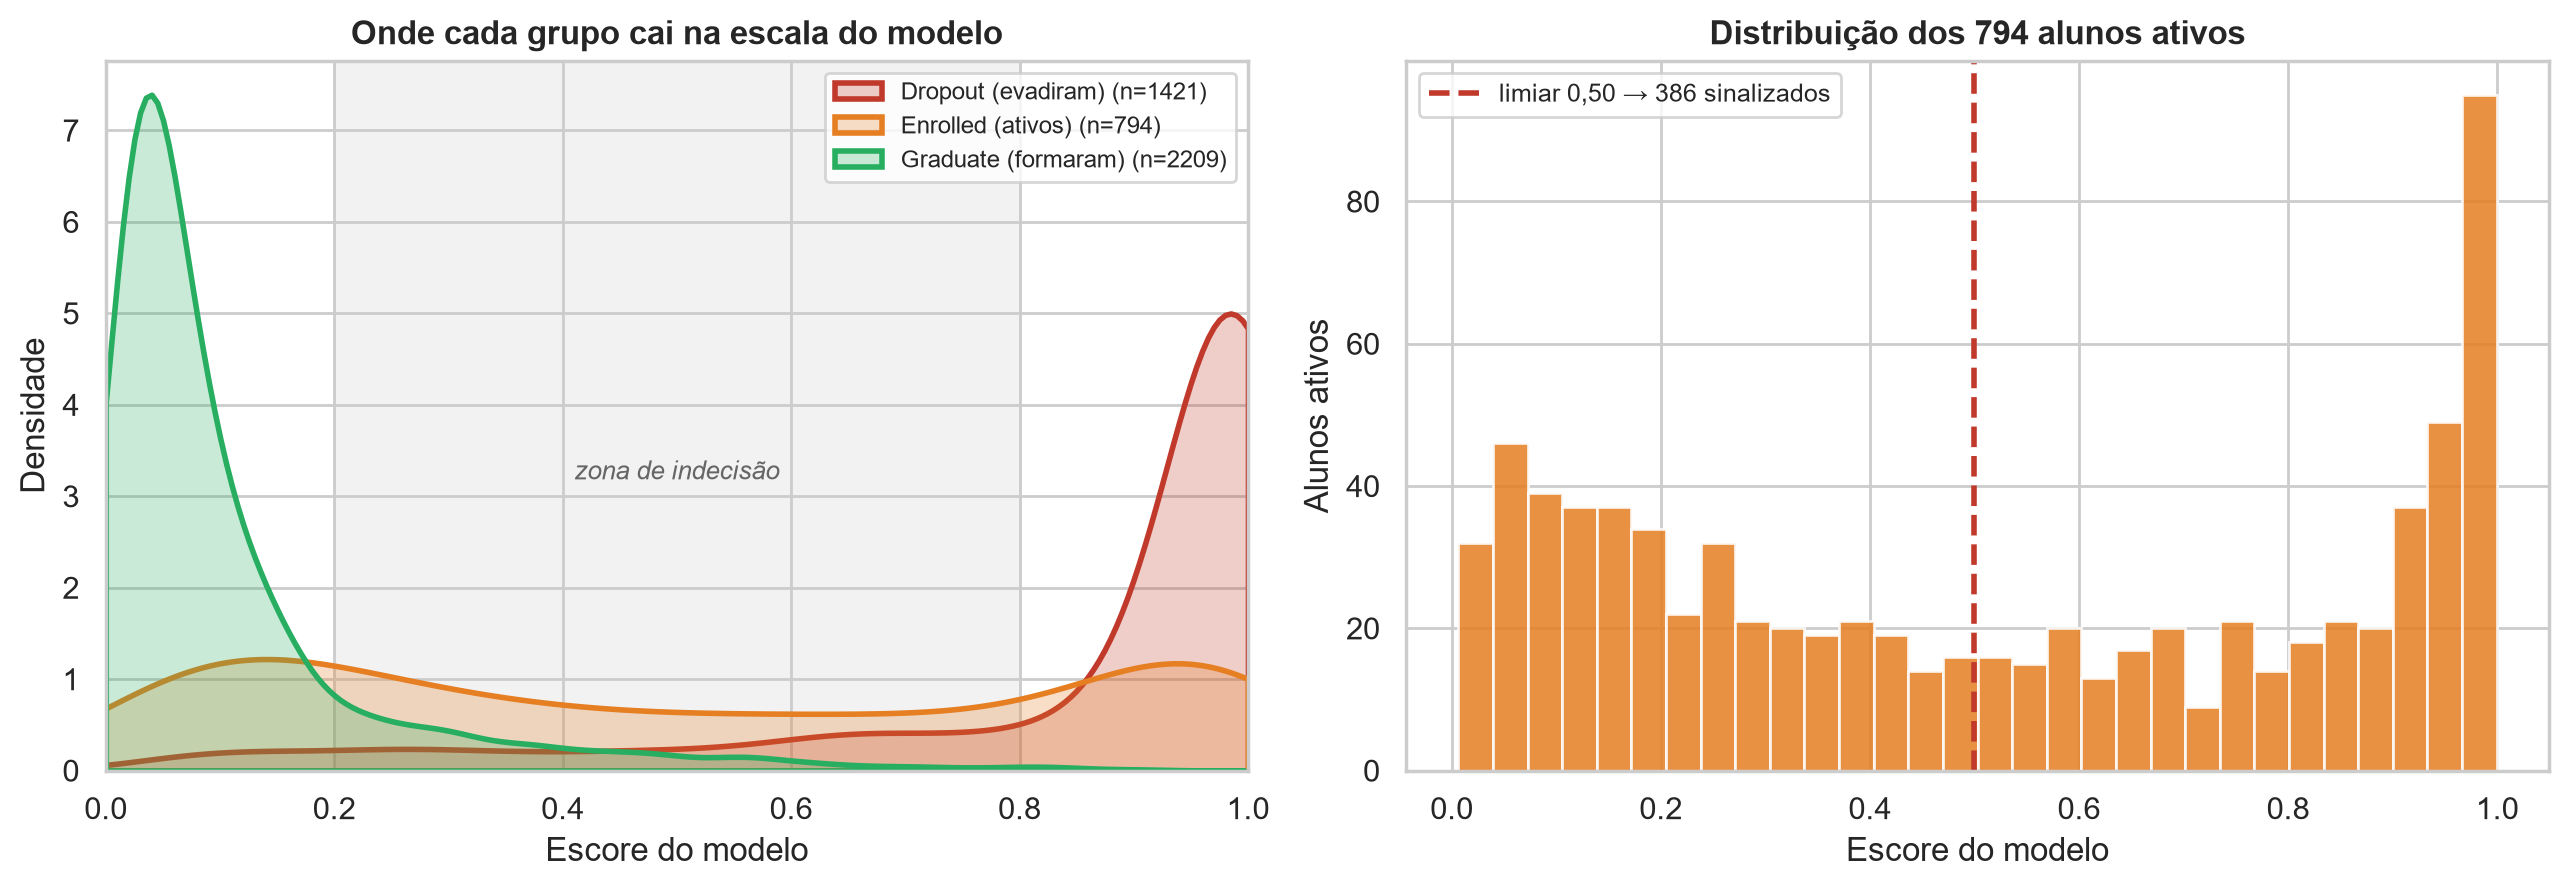

In [15]:
fig("26_alunos_ativos_distribuicao.png")

Os concluídos ficam nos extremos; **os ativos ficam no meio**. Consequência direta de o modelo nunca ter
visto essa população. **A L-01 deixa de ser ressalva formal e passa a ter número.**

Sinalizar quase metade dos ativos não é política de intervenção — é uma lista que ninguém atende. A
saída é **partir da capacidade**: com 50 vagas de monitoria, convoque os 50 de maior escore. O modelo
ordena, a instituição corta.

In [16]:
print("A ENTREGA — lista priorizada dos 794 alunos ativos")
print()
print(ativos.head(6)[["prioridade", "escore", "faixa", "fator_1", "area"]].to_string(index=False))
print()
print("distribuição por faixa de risco:")
for k in ["Muito alto", "Alto", "Moderado", "Baixo"]:
    n = int((ativos.faixa == k).sum())
    print(f"   {k:<12} {n:>4}  ({n/len(ativos):>5.1%})")
print()
duplo = int((ativos.area_secundaria != "—").sum())
print(f"{duplo} alunos ({duplo/len(ativos):.1%}) têm risco em MAIS DE UMA área —")
print("são os que escapam de fluxos institucionais, porque cada setor os trata como caso do outro.")

A ENTREGA — lista priorizada dos 794 alunos ativos

 prioridade  escore      faixa                             fator_1       area
          1  0.9995 Muito alto Disciplinas aprovadas (2º sem.) = 0 Pedagógico
          2  0.9994 Muito alto Disciplinas aprovadas (2º sem.) = 0 Pedagógico
          3  0.9992 Muito alto Disciplinas aprovadas (2º sem.) = 0 Pedagógico
          4  0.9990 Muito alto Disciplinas aprovadas (2º sem.) = 2 Pedagógico
          5  0.9988 Muito alto Disciplinas aprovadas (2º sem.) = 0 Pedagógico
          6  0.9987 Muito alto Disciplinas aprovadas (2º sem.) = 1 Pedagógico

distribuição por faixa de risco:
   Muito alto    181  (22.8%)
   Alto          105  (13.2%)
   Moderado      150  (18.9%)
   Baixo         358  (45.1%)

442 alunos (55.7%) têm risco em MAIS DE UMA área —
são os que escapam de fluxos institucionais, porque cada setor os trata como caso do outro.
